In [37]:
import pandas as pd
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
import matplotlib.pyplot as plt
import seaborn as sns
import json
import tempfile
import numpy as np

# Import tools for preprocessing and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Import all models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier


# Import from imbalanced-learn
from imblearn.pipeline import Pipeline as ImblearnPipeline
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import ADASYN
from sklearn.base import clone

# Ignore Warning
import warnings
warnings.filterwarnings('ignore')

# Set plot style
sns.set_style("whitegrid")

## 1. Load and Prepare the Data

Load the data

In [2]:
try:
    df = pd.read_csv('fraud_detection.csv')
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: 'fraud_detection.csv' not found. Please ensure the file is in the same directory as your notebook.")

Dataset loaded successfully.


Do simple EDA

In [3]:
df.sample(10)

,transaction_id,amount,merchant_type,device_type,label
289,290,89.36,electronics,mobile,0
931,932,180.14,clothing,desktop,1
790,791,16.65,travel,mobile,0
696,697,34.06,groceries,mobile,0
792,793,70.50,clothing,desktop,0
365,366,48.79,clothing,mobile,0
710,711,142.81,groceries,tablet,0
266,267,119.41,travel,tablet,0
73,74,168.99,travel,tablet,0
682,683,18.74,travel,desktop,0


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  1000 non-null   int64  
 1   amount          1000 non-null   float64
 2   merchant_type   1000 non-null   object 
 3   device_type     1000 non-null   object 
 4   label           1000 non-null   int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 39.2+ KB


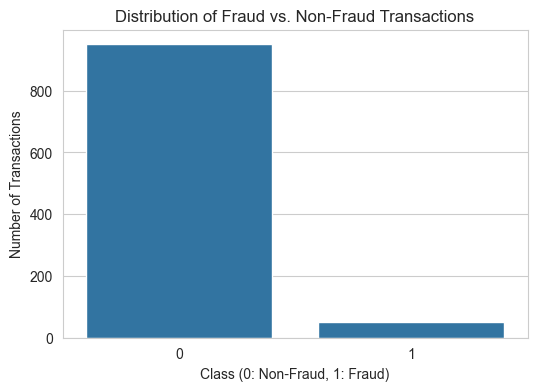

label
0    0.95
1    0.05
Name: proportion, dtype: float64


In [4]:
# Target Variable Distribution ('label')
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df)
plt.title('Distribution of Fraud vs. Non-Fraud Transactions')
plt.xlabel('Class (0: Non-Fraud, 1: Fraud)')
plt.ylabel('Number of Transactions')
plt.show()
print(df['label'].value_counts(normalize=True))

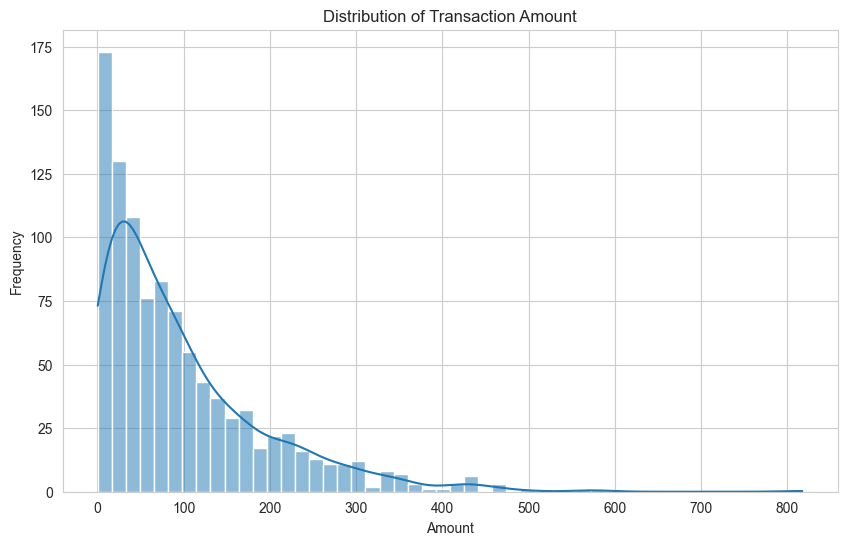

In [5]:
# Transaction Amount Analysis
plt.figure(figsize=(10, 6))
sns.histplot(df['amount'], bins=50, kde=True)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.show()

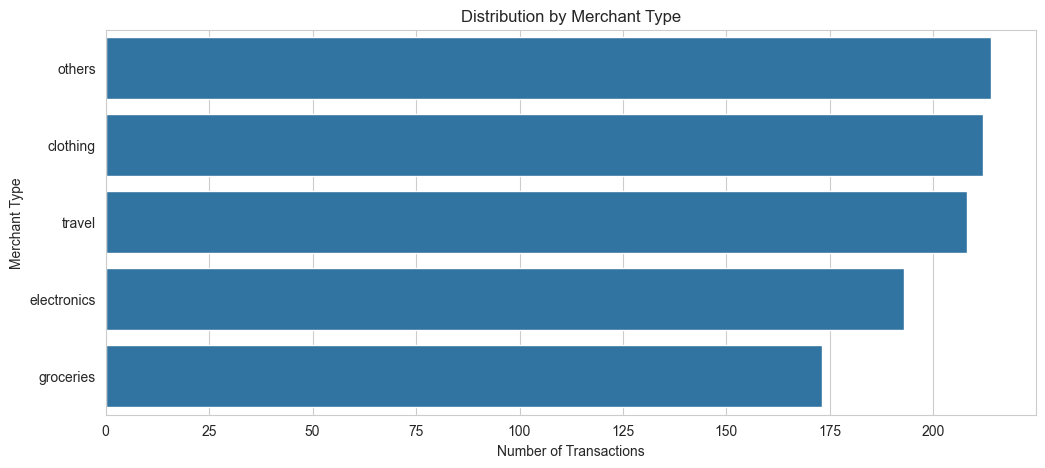

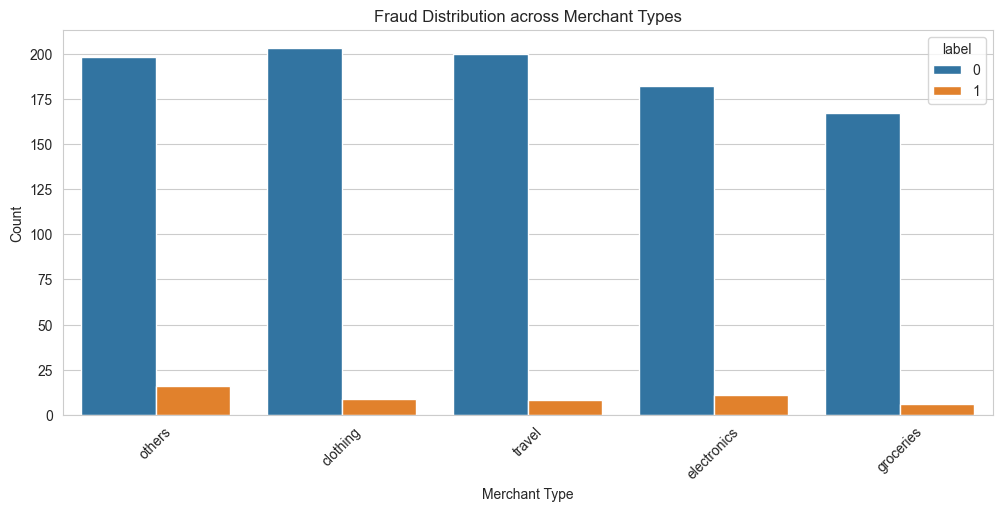

In [6]:
# Categorical Feature Analysis ('merchant_type' and 'device_type')
plt.figure(figsize=(12, 5))
sns.countplot(y='merchant_type', data=df, order=df['merchant_type'].value_counts().index)
plt.title('Distribution by Merchant Type')
plt.xlabel('Number of Transactions')
plt.ylabel('Merchant Type')
plt.show()

plt.figure(figsize=(12, 5))
sns.countplot(x='merchant_type', data=df, hue='label', order=df['merchant_type'].value_counts().index)
plt.title('Fraud Distribution across Merchant Types')
plt.xlabel('Merchant Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

## 2. Data Preparation & Preprocessing

In [7]:
# Separate features (X) and target (y)
X = df.drop(['transaction_id', 'label'], axis=1)
y = df['label']

In [39]:
# Apply log transformation
numerical_pipeline = SklearnPipeline(steps=[
    ('log_transformer', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

In [8]:
# Identify categorical features
categorical_features = ['merchant_type', 'device_type']
numerical_features = ['amount']

In [40]:
# Create a preprocessor to handle one-hot encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

In [41]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (800, 3)
Testing data shape: (200, 3)


## 3. MLflow Experiment Tracking

*RUN MLFLOW SERVER FIRST !* to do it, on your terminal, run this : ``mlflow server --backend-store-uri file:///path/to/your/mlflow_data --default-artifact-root file:///path/to/your/mlflow_data ``, note that you have to create a folder to put your mlflow data, if you are not doing this, next time you run the experiment, it will prompt an error

In [12]:
# Set the MLflow experiment


experiment_description = (
    "This is the frraud detection project by DeployCamp Team 12 "
    "This experiment contains the produce models for fraud."
)

experiment_tags = {
    "project_name": "Fraud_Detection",
    "store_dept": "produce",
    "team": "deploycamp_team_12",
    "project_quarter": "Q3-2025",
    "mlflow.note.content": experiment_description,
}

In [24]:
# RUN ONLY ONCE!
client = MlflowClient(tracking_uri="http://127.0.0.1:5000")
produce_fraud_experiment = client.create_experiment(name="Fraud_Detection", tags=experiment_tags)

RestException: RESOURCE_ALREADY_EXISTS: Experiment 'Fraud_Detection_New' already exists.

In [25]:
mlflow.set_experiment("Fraud_Detection_New")
mlflow.set_tracking_uri("http://127.0.0.1:5000")


In [26]:
print(mlflow.get_tracking_uri())
print(mlflow.get_artifact_uri())

2025/07/20 13:03:21 WARNING mlflow.tracking.fluent: No active run found. A new active run will be created. If this is not intended, please create a run using `mlflow.start_run()` first.


http://127.0.0.1:5000
file:///D:\mlflow_data/569221346272143222/2ebc7c9300b04d57a3248e1d05c84496/artifacts


In [27]:
def log_confusion_matrix_plot(y_true, y_pred, run_name):
    """Generates, saves, and logs a confusion matrix plot as an MLflow artifact."""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    
    # Save the plot to a file
    figure_path = f"{run_name}_confusion_matrix.png"
    plt.savefig(figure_path)
    plt.close() # Close the plot to avoid displaying it in the notebook
    
    # Log the plot as an artifact
    mlflow.log_artifact(figure_path, "plots")

In [75]:
def train_and_evaluate_model(model, model_name, X_train, y_train, X_test, y_test):
    """
    Trains a model and logs parameters and a comprehensive set of metrics to MLflow.
    """
    # --- Run 1: Without Class Weighting (Baseline) ---
    run_name_baseline = f"{name}_NoWeighting"
    with mlflow.start_run(run_name=run_name_baseline):
        pipeline_baseline = SklearnPipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
        pipeline_baseline.fit(X_train, y_train)
        y_pred = pipeline_baseline.predict(X_test)
        y_pred_proba = pipeline_baseline.predict_proba(X_test)[:, 1]

        # Log metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test, y_pred, zero_division=0))

        print(f"Test F1 Score: {f1:.4f}")
        print(f"Test ROC AUC: {roc_auc:.4f}")
        print(f"Test PR AUC: {pr_auc:.4f}")

        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", "None")
        mlflow.sklearn.log_model(
            pipeline_baseline,
            artifact_path=name, # Explicitly using artifact_path
            input_example=X_train.head()
            )
        log_confusion_matrix_plot(y_test, y_pred, run_name_baseline)

    # --- Run 2: With Class Weighting ---
    run_name_weight = f"{name}_ClassWeight"
    with mlflow.start_run(run_name=run_name_weight):
        weighted_model = clone(model)
        imbalance_strategy = "None"
        if name in ["XGBoost", "LightGBM"]:
            weighted_model.set_params(scale_pos_weight=scale_pos_weight_value)
            imbalance_strategy = "scale_pos_weight"
        elif name in ["LogisticRegression", "RandomForest"]:
            weighted_model.set_params(class_weight='balanced')
            imbalance_strategy = "class_weight='balanced'"
        
        pipeline_weighted = SklearnPipeline(steps=[('preprocessor', preprocessor), ('classifier', weighted_model)])
        pipeline_weighted.fit(X_train, y_train)
        y_pred = pipeline_weighted.predict(X_test)
        y_pred_proba = pipeline_weighted.predict_proba(X_test)[:, 1]
        
        # Log metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test, y_pred, zero_division=0))

        print(f"Test F1 Score: {f1:.4f}")
        print(f"Test ROC AUC: {roc_auc:.4f}")
        print(f"Test PR AUC: {pr_auc:.4f}")

        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", imbalance_strategy)
        mlflow.sklearn.log_model(
            pipeline_weighted,
            artifact_path=name, # Explicitly using artifact_path
            input_example=X_train.head()
            )
        log_confusion_matrix_plot(y_test, y_pred, run_name_baseline)

    # --- Run 3: With SMOTE-Tomek ---
    run_name_smotetomek = f"{name}_SMOTETomek"
    with mlflow.start_run(run_name=run_name_smotetomek):
        pipeline_smotetomek = ImblearnPipeline(steps=[
            ('preprocessor', preprocessor),
            ('sampler', SMOTETomek(random_state=42)),
            ('classifier', model)
        ])
        pipeline_smotetomek.fit(X_train, y_train)
        y_pred = pipeline_smotetomek.predict(X_test)
        y_pred_proba = pipeline_smotetomek.predict_proba(X_test)[:, 1]

        # Log metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test, y_pred, zero_division=0))

        print(f"Test F1 Score: {f1:.4f}")
        print(f"Test ROC AUC: {roc_auc:.4f}")
        print(f"Test PR AUC: {pr_auc:.4f}")

        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", "SMOTE-Tomek")
        mlflow.sklearn.log_model(
            pipeline_smotetomek,
            artifact_path=name, # Explicitly using artifact_path
            input_example=X_train.head()
            )
        log_confusion_matrix_plot(y_test, y_pred, run_name_baseline)

    # --- Run 4: With ADASYN ---
    run_name_adasyn = f"{name}_ADASYN"
    with mlflow.start_run(run_name=run_name_adasyn):
        pipeline_adasyn = ImblearnPipeline(steps=[
            ('preprocessor', preprocessor),
            ('adasyn', ADASYN(random_state=42)),
            ('classifier', model)
        ])
        pipeline_adasyn.fit(X_train, y_train)
        y_pred = pipeline_adasyn.predict(X_test)
        y_pred_proba = pipeline_adasyn.predict_proba(X_test)[:, 1]
        
        # Log metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test, y_pred, zero_division=0))

        print(f"Test F1 Score: {f1:.4f}")
        print(f"Test ROC AUC: {roc_auc:.4f}")
        print(f"Test PR AUC: {pr_auc:.4f}")

        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", "ADASYN")
        mlflow.sklearn.log_model(
            pipeline_adasyn,
            artifact_path=name, # Explicitly using artifact_path
            input_example=X_train.head()
            )
        log_confusion_matrix_plot(y_test, y_pred, run_name_baseline)

In [31]:
# Define the models to compare
models_to_compare = {
    "LogisticRegression": LogisticRegression(random_state=42, max_iter=1000),
    "RandomForest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(random_state=42),
    "MLPClassifier": MLPClassifier(random_state=42, max_iter=1000),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Support Vector Machine": SVC(random_state=42, probability=True),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}

In [32]:
# Calculate the weight for the minority class once
scale_pos_weight_value = y_train.value_counts()[0] / y_train.value_counts()[1]

In [29]:
mlflow.end_run()

🏃 View run sedate-kit-690 at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/2ebc7c9300b04d57a3248e1d05c84496
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


In [42]:
# Loop through models, train, and log
for name, model in models_to_compare.items():
    print(f"\n--- Processing Model: {name} ---")
    train_and_evaluate_model(model, name, X_train, y_train, X_test, y_test)
    print(f"--- Model {name} Processed ! ---\n")


print("\n✅ All experiments are complete and have been logged to MLflow.")


--- Processing Model: LogisticRegression ---


2025/07/20 13:56:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 13:56:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run LogisticRegression_NoWeighting at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/2430a4e473734855b43ac90b09f15fe5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


2025/07/20 13:56:09 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 13:56:12 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run LogisticRegression_ClassWeight at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/0d6016e883084e12b3e4acc67e7afdd1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


...

🏃 View run CatBoost_ClassWeight at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/291a8d7cc2a2434cb20f6d24442dad3f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


2025/07/20 13:58:13 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 13:58:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run CatBoost_SMOTETomek at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/32d6307205e4482b8fe81ce1cd7a35e7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


2025/07/20 13:58:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 13:58:23 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run CatBoost_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/24ba2592fba54144bb99e4b5a5ac8a50
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Model CatBoost Processed ! ---


✅ All experiments are complete and have been logged to MLflow.


Hyperparameter Tuning for Advanced Model (XGBoost, LightBM, CatBoos)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Define models
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
lgbm = LGBMClassifier(random_state=42)
catboost = CatBoostClassifier(verbose=0, random_state=42)

# Define parameter distributions for each model
# Remember to use the 'classifier__' prefix
xgb_param_dist = {
    'classifier__n_estimators': [100, 200, 500],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_depth': [8, 10, 12],
    'classifier__scale_pos_weight': [25, 50, 75, 100]
}

lgbm_param_dist = {
    'classifier__n_estimators': [100, 200, 500],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__num_leaves': [20, 31, 40],
    'classifier__scale_pos_weight': [25, 50, 75, 100]
}

catboost_param_dist = {
    'classifier__iterations': [100, 200, 500],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__depth': [4, 6, 8],
    'classifier__scale_pos_weight': [25, 50, 75, 100]
}

In [44]:
models_to_tune = [
    ('XGBoost', xgb, xgb_param_dist),
    ('LightGBM', lgbm, lgbm_param_dist),
    ('CatBoost', catboost, catboost_param_dist)
]

In [46]:
# Choose your single best imbalance strategy
best_sampler = ADASYN(random_state=42)

for name, model, param_dist in models_to_tune:
    # Create the full pipeline
    tuning_pipeline = ImblearnPipeline(steps=[
        ('preprocessor', preprocessor),
        ('sampler', best_sampler),
        ('classifier', model)
    ])

    # Set up and run RandomizedSearchCV
    random_search = RandomizedSearchCV(
        tuning_pipeline,
        param_distributions=param_dist,
        n_iter=25,
        cv=3,
        scoring='f1',
        n_jobs=-1,
        random_state=42
    )

    print(f"--- Starting hyperparameter tuning for {name} ---")
    random_search.fit(X_train, y_train)
    print(f"--- Tuning finished for {name} ---")

    # Log the results to MLflow
    run_name = f"{name}_Tuned_with_ADASYN"
    with mlflow.start_run(run_name=run_name):
        # Log parameters
        mlflow.log_params(random_search.best_params_)
        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", "ADASYN")
        
        # Log the best cross-validation score
        mlflow.log_metric("best_cv_f1_score", random_search.best_score_)

        # Evaluate the best model on the test set
        best_model = random_search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_pred_proba = best_model.predict_proba(X_test)[:, 1]

        # Log all test metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test, y_pred, zero_division=0))

        # Log model artifact with an input example
        mlflow.sklearn.log_model(
            sk_model=best_model,
            artifact_path=f"tuned_{name}_model",
            input_example=X_train.head()
        )
        
        # Log the confusion matrix as a plot
        log_confusion_matrix_plot(y_test, y_pred, run_name)
        
        print(f"\n✅ Tuned {name} model and results logged to MLflow.\n")

--- Starting hyperparameter tuning for XGBoost ---
--- Tuning finished for XGBoost ---


2025/07/20 14:12:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 14:12:12 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Tuned XGBoost model and results logged to MLflow.

🏃 View run XGBoost_Tuned_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/fe016d00ae774b90a9af921c94e8b51f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Starting hyperparameter tuning for LightGBM ---
[LightGBM] [Info] Number of positive: 748, number of negative: 760
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000330 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 541
[LightGBM] [Info] Number of data points in the train set: 1508, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.496021 -> initscore=-0.015915
[LightGBM] [Info] Start training from score -0.015915
--- Tuning finished for LightGBM ---


2025/07/20 14:12:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 14:12:23 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Tuned LightGBM model and results logged to MLflow.

🏃 View run LightGBM_Tuned_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/28077d1a4a1e4629b0d109d116cfbc18
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Starting hyperparameter tuning for CatBoost ---
--- Tuning finished for CatBoost ---


2025/07/20 14:12:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 14:12:45 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Tuned CatBoost model and results logged to MLflow.

🏃 View run CatBoost_Tuned_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/0585630df4b74cf3909d6c64266ff29f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


Hyperparameter Tuning for Top 3 Model (Random Forest, LogReg, AdaBoost)

In [50]:
rf = RandomForestClassifier(random_state=42)
ada = AdaBoostClassifier(random_state=42)
lr = LogisticRegression(random_state=42, max_iter=1000) # Increase max_iter to ensure convergence for some solvers

In [47]:
# Remember the 'classifier__' prefix is necessary for pipelines
rf_param_dist = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

ada_param_dist = {
    'classifier__n_estimators': [50, 100, 200, 500],
    'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0]
}

lr_param_dist = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear'] # liblinear is a good choice as it supports both L1 and L2
}

In [51]:
models_to_tune = [
    ('RandomForest', rf, rf_param_dist),
    ('AdaBoost', ada, ada_param_dist),
    ('LogisticRegression', lr, lr_param_dist)
]

In [53]:
# Loop through each model to tune and log it
for name, model, param_dist in models_to_tune:
    # Create the full pipeline
    tuning_pipeline = ImblearnPipeline(steps=[
        ('preprocessor', preprocessor),
        ('sampler', best_sampler),
        ('classifier', model)
    ])

    # Set up and run RandomizedSearchCV
    random_search = RandomizedSearchCV(
        tuning_pipeline,
        param_distributions=param_dist,
        n_iter=50,
        cv=3,
        scoring='f1',
        n_jobs=-1,
        random_state=42
    )

    print(f"--- Starting hyperparameter tuning for {name} ---")
    random_search.fit(X_train, y_train)
    print(f"--- Tuning finished for {name} ---")

    # Log the best result to MLflow
    run_name = f"{name}_Tuned_with_ADASYN"
    with mlflow.start_run(run_name=run_name):
        # Log parameters
        mlflow.log_params(random_search.best_params_)
        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", "ADASYN")
        
        # Log the best cross-validation score
        mlflow.log_metric("best_cv_f1_score", random_search.best_score_)

        # Evaluate the best model on the test set
        best_model = random_search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_pred_proba = best_model.predict_proba(X_test)[:, 1]

        # Log all test metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric("precision", precision_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test, y_pred, zero_division=0))

        # Log model artifact with an input example
        mlflow.sklearn.log_model(
            sk_model=best_model,
            artifact_path=f"tuned_{name}_model",
            input_example=X_train.head()
        )
        
        # Log the confusion matrix as a plot
        log_confusion_matrix_plot(y_test, y_pred, run_name)
        
        print(f"\n✅ Tuned {name} model and results logged to MLflow.\n")


--- Starting hyperparameter tuning for RandomForest ---
--- Tuning finished for RandomForest ---


2025/07/20 14:35:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 14:35:07 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Tuned RandomForest model and results logged to MLflow.

🏃 View run RandomForest_Tuned_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/92233432fff24dba936ae9f6057ac001
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Starting hyperparameter tuning for AdaBoost ---
--- Tuning finished for AdaBoost ---


2025/07/20 14:35:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 14:35:15 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Tuned AdaBoost model and results logged to MLflow.

🏃 View run AdaBoost_Tuned_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/504c2e2bae50406bab9c04e1d28f2b13
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Starting hyperparameter tuning for LogisticRegression ---
--- Tuning finished for LogisticRegression ---


2025/07/20 14:35:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 14:35:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Tuned LogisticRegression model and results logged to MLflow.

🏃 View run LogisticRegression_Tuned_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/6f60e32e242342c985178ff1926194da
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


## 4. Feature Engineering + GridSearchCV

let's try to do feature engineering for the initial dataset, hoping to improve our model result

In [55]:
print("Loading original data...")
try:
    df_fe = df.copy() # Use a copy for feature engineering
    print("Data loaded successfully.")
except FileNotFoundError:
    print("Error: 'fraud_detection.csv' not found.")
    # Create a dummy dataframe to prevent errors if the file is not found
    df_fe = pd.DataFrame()

Loading original data...
Data loaded successfully.


In [56]:
if not df_fe.empty:
    # --- 2. Apply Feature Engineering Techniques ---
    print("\nStarting feature engineering...")

    # a) Amount-Based Features
    # Create amount bins
    bins = [0, 25, 100, 500, float('inf')]
    labels = ['low', 'medium', 'high', 'very_high']
    df_fe['amount_category'] = pd.cut(df_fe['amount'], bins=bins, labels=labels, right=False)
    print("- Created 'amount_category' feature.")

    # Check for round number transactions
    df_fe['is_round_amount'] = (df_fe['amount'] % 1 == 0).astype(int)
    print("- Created 'is_round_amount' feature.")

    # b) Interaction Features
    # Combine merchant_type and device_type
    df_fe['merchant_device_combo'] = df_fe['merchant_type'] + '_' + df_fe['device_type']
    print("- Created 'merchant_device_combo' interaction feature.")

    # c) Behavioral/Statistical Features
    # Calculate deviation from the mean amount for the merchant type
    mean_amount_by_merchant = df_fe.groupby('merchant_type')['amount'].transform('mean')
    df_fe['amount_deviation_from_merchant_mean'] = df_fe['amount'] - mean_amount_by_merchant
    print("- Created 'amount_deviation_from_merchant_mean' behavioral feature.")

    print("\nFeature engineering complete. New DataFrame head:")
    print(df_fe.head())

    # --- 3. Prepare the New, Enriched Dataset for Modeling ---
    print("\nPreparing new dataset for modeling...")

    # Separate features (X) and target (y)
    X_fe = df_fe.drop(['transaction_id', 'label'], axis=1)
    y_fe = df_fe['label']

    # Update the feature lists to include our new engineered features
    categorical_features_fe = [
        'merchant_type',
        'device_type',
        'amount_category',      # New categorical feature
        'merchant_device_combo' # New categorical feature
    ]
    numerical_features_fe = [
        'amount',
        'is_round_amount',      # New numerical feature
        'amount_deviation_from_merchant_mean' # New numerical feature
    ]

    # Re-define the preprocessor for the new feature set
    # We'll keep the log transform pipeline for the amount
    numerical_pipeline = SklearnPipeline(steps=[
        ('log_transformer', FunctionTransformer(np.log1p)),
        ('scaler', StandardScaler())
    ])

    # The new preprocessor will handle the original and engineered features
    preprocessor_fe = ColumnTransformer(
        transformers=[
            # Apply the log-scaler pipeline only to the original 'amount'
            ('num_log_scaled', numerical_pipeline, ['amount']),
            # Apply standard scaling to the other new numerical features
            ('num_scaled', StandardScaler(), ['is_round_amount', 'amount_deviation_from_merchant_mean']),
            # One-hot encode all categorical features
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features_fe)
        ],
        remainder='passthrough'
    )

    # Split the new data into training and testing sets
    X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
        X_fe, y_fe, test_size=0.2, random_state=42, stratify=y_fe
    )

    print("\nNew dataset is ready for training.")
    print(f"Training data shape: {X_train_fe.shape}")
    print(f"Testing data shape: {X_test_fe.shape}")



Starting feature engineering...
- Created 'amount_category' feature.
- Created 'is_round_amount' feature.
- Created 'merchant_device_combo' interaction feature.
- Created 'amount_deviation_from_merchant_mean' behavioral feature.

Feature engineering complete. New DataFrame head:
   transaction_id  amount merchant_type device_type  label amount_category  \
0               1   46.93        travel      tablet      0          medium   
1               2  301.01     groceries     desktop      0            high   
2               3  131.67        others      tablet      0            high   
3               4   91.29   electronics     desktop      0          medium   
4               5   16.96        others      mobile      0             low   

   is_round_amount merchant_device_combo  amount_deviation_from_merchant_mean  
0                0         travel_tablet                           -56.343510  
1                0     groceries_desktop                           205.813006  
2         

In [61]:
# Define the models to tune
rf = RandomForestClassifier(random_state=42)
ada = AdaBoostClassifier(random_state=42)
lr = LogisticRegression(random_state=42, max_iter=1000)

In [65]:
# Define the parameter distributions for each model
rf_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

ada_param_grid = {
    'classifier__n_estimators': [50, 100, 200, 500],
    'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0]
}

lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear']
}

In [60]:
from sklearn.model_selection import GridSearchCV

In [66]:
# Organize models and parameters into a list for the loop
models_to_tune = [
    ('RandomForest', rf, rf_param_grid),
    ('AdaBoost', ada, ada_param_grid),
    ('LogisticRegression', lr, lr_param_grid)
]

# Choose your best-performing imbalance strategy
best_sampler = ADASYN(random_state=42)

# Loop through each model to tune and log it using the FEATURE ENGINEERED data
for name, model, param_grid in models_to_tune:
    # Create the full pipeline using the new preprocessor_fe
    tuning_pipeline = ImblearnPipeline(steps=[
        ('preprocessor', preprocessor_fe), # IMPORTANT: Using the new preprocessor
        ('sampler', best_sampler),
        ('classifier', model)
    ])

    # Set up and run GridSearchCV
    grid_search = GridSearchCV(
        tuning_pipeline,
        param_grid=param_grid, # Changed from param_distributions
        cv=3,
        scoring='f1',
        n_jobs=-1
    )

    print(f"--- Starting FE-GridSearch-Tuning for {name} ---")
    # Use the new feature-engineered training data
    grid_search.fit(X_train_fe, y_train_fe)
    print(f"--- FE-GridSearch-Tuning finished for {name} ---")

    # Log the best result to MLflow
    run_name = f"FE_GridSearch_Tuned_{name}_with_ADASYN"
    with mlflow.start_run(run_name=run_name):
        # Log parameters
        mlflow.log_params(grid_search.best_params_)
        mlflow.log_param("model_name", name)
        mlflow.log_param("imbalance_strategy", "ADASYN")
        mlflow.log_param("feature_engineering_version", "v1") # Tag the run

        # Log the best cross-validation score
        mlflow.log_metric("best_cv_f1_score", grid_search.best_score_)

        # Evaluate the best model on the new feature-engineered test set
        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test_fe)
        y_pred_proba = best_model.predict_proba(X_test_fe)[:, 1]

        # Log all test metrics
        mlflow.log_metric("pr_auc", average_precision_score(y_test_fe, y_pred_proba))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test_fe, y_pred_proba))
        mlflow.log_metric("accuracy", accuracy_score(y_test_fe, y_pred))
        mlflow.log_metric("precision", precision_score(y_test_fe, y_pred, zero_division=0))
        mlflow.log_metric("recall", recall_score(y_test_fe, y_pred, zero_division=0))
        mlflow.log_metric("f1_score", f1_score(y_test_fe, y_pred, zero_division=0))

        # Log model artifact with an input example
        mlflow.sklearn.log_model(
            sk_model=best_model,
            artifact_path=f"fe_tuned_{name}_model",
            input_example=X_train_fe.head()
        )
        
        # Log the confusion matrix as a plot
        log_confusion_matrix_plot(y_test_fe, y_pred, run_name)
        
        print(f"\n✅ FE-Tuned {name} model and results logged to MLflow.\n")

--- Starting FE-GridSearch-Tuning for RandomForest ---
--- FE-GridSearch-Tuning finished for RandomForest ---


2025/07/20 15:01:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 15:01:25 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '     amount merchant_type device_type amount_category  is_round_amount  \\\n876  125.87     groceries     desktop            high                0   \n75   130.57   electronics     desktop            high                0   \n832   15.18   electronics      mobile             low                0   \n155   27.71   electronics      tablet          medium                0   \n181   12.04        others      tablet             low                0   \n\n    merchant_device_combo  amount_deviation_from_merchant_mean  \n876     groceries_desktop                            30.673006  \n75    electronics_desktop                            29.279637  \n832    electronics_mobile                           -86.110363  \n155 


✅ FE-Tuned RandomForest model and results logged to MLflow.

🏃 View run FE_GridSearch_Tuned_RandomForest_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/8e20a1a0811141ca9f8234b79a3790ef
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Starting FE-GridSearch-Tuning for AdaBoost ---
--- FE-GridSearch-Tuning finished for AdaBoost ---


2025/07/20 15:01:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 15:01:33 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '     amount merchant_type device_type amount_category  is_round_amount  \\\n876  125.87     groceries     desktop            high                0   \n75   130.57   electronics     desktop            high                0   \n832   15.18   electronics      mobile             low                0   \n155   27.71   electronics      tablet          medium                0   \n181   12.04        others      tablet             low                0   \n\n    merchant_device_combo  amount_deviation_from_merchant_mean  \n876     groceries_desktop                            30.673006  \n75    electronics_desktop                            29.279637  \n832    electronics_mobile                           -86.110363  \n155 


✅ FE-Tuned AdaBoost model and results logged to MLflow.

🏃 View run FE_GridSearch_Tuned_AdaBoost_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/d42950009b1d4ad6861fd4374a134196
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222
--- Starting FE-GridSearch-Tuning for LogisticRegression ---
--- FE-GridSearch-Tuning finished for LogisticRegression ---


2025/07/20 15:01:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2025/07/20 15:01:37 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '     amount merchant_type device_type amount_category  is_round_amount  \\\n876  125.87     groceries     desktop            high                0   \n75   130.57   electronics     desktop            high                0   \n832   15.18   electronics      mobile             low                0   \n155   27.71   electronics      tablet          medium                0   \n181   12.04        others      tablet             low                0   \n\n    merchant_device_combo  amount_deviation_from_merchant_mean  \n876     groceries_desktop                            30.673006  \n75    electronics_desktop                            29.279637  \n832    electronics_mobile                           -86.110363  \n155 


✅ FE-Tuned LogisticRegression model and results logged to MLflow.

🏃 View run FE_GridSearch_Tuned_LogisticRegression_with_ADASYN at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/ae2df4cb03a545de8e97bf5655e58ebb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


## 5. Use IsolationForest to classify what "Normal" Transaction should be

In [67]:
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline as SklearnPipeline
import numpy as np
import mlflow

In [68]:
# --- 1. Prepare the Training Data ---
# Isolation Forest is an unsupervised algorithm that should ideally be trained
# only on "normal" (non-fraudulent) data.
print("Preparing data for Isolation Forest...")
# We select only the non-fraudulent transactions for training
X_train_normal = X_train[y_train == 0]
print(f"Training on {len(X_train_normal)} normal transactions.")

Preparing data for Isolation Forest...
Training on 760 normal transactions.


In [ ]:
# --- 2. Define the Isolation Forest Model ---
# The 'contamination' parameter is the most important one to set.
# It's the expected proportion of anomalies in the data.
# Let's calculate it from our training set.
contamination_rate = y_train.value_counts(normalize=True)[1] # The percentage of fraud cases

# Create the model. We'll set contamination to our calculated rate.
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=contamination_rate,
    random_state=42,
    n_jobs=-1
)

In [70]:
# Create the full pipeline using the original preprocessor
# We don't need a sampler (like ADASYN) for this unsupervised approach.
iso_forest_pipeline = SklearnPipeline(steps=[
    ('preprocessor', preprocessor), # Using the original preprocessor
    ('model', iso_forest)
])

In [71]:
# --- 3. Train the Model ---
print("\nTraining Isolation Forest model...")
# Fit the pipeline on the NORMAL training data
iso_forest_pipeline.fit(X_train_normal)
print("Training complete.")


Training Isolation Forest model...
Training complete.


In [73]:
# --- 4. Evaluate the Model and Log to MLflow ---
run_name = "IsolationForest_Experiment"
with mlflow.start_run(run_name=run_name):
    print(f"\nLogging results for run: {run_name}")
    
    # Make predictions on the full test set (which includes fraud and non-fraud)
    y_pred_iso = iso_forest_pipeline.predict(X_test)

    # The model predicts -1 for anomalies (fraud) and 1 for inliers (normal).
    # We need to map these to 1 (fraud) and 0 (normal) to calculate metrics.
    y_pred_mapped = np.array([1 if x == -1 else 0 for x in y_pred_iso])

    y_scores = -iso_forest_pipeline.decision_function(X_test)

    # Log parameters
    mlflow.log_param("model_name", "IsolationForest")
    mlflow.log_param("contamination_rate", contamination_rate)
    
# Log test metrics based on hard predictions
    f1 = f1_score(y_test, y_pred_mapped, zero_division=0)
    precision = precision_score(y_test, y_pred_mapped, zero_division=0)
    recall = recall_score(y_test, y_pred_mapped, zero_division=0)
    accuracy = accuracy_score(y_test, y_pred_mapped)

    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("accuracy", accuracy)

    # Log test metrics based on anomaly scores for AUC
    roc_auc = roc_auc_score(y_test, y_scores)
    pr_auc = average_precision_score(y_test, y_scores)

    mlflow.log_metric("roc_auc", roc_auc)
    mlflow.log_metric("pr_auc", pr_auc)

    print(f"Test F1 Score: {f1:.4f}")
    print(f"Test ROC AUC: {roc_auc:.4f}")
    print(f"Test PR AUC: {pr_auc:.4f}")

    # Log the model artifact
    mlflow.sklearn.log_model(
        sk_model=iso_forest_pipeline,
        artifact_path="isolation_forest_model",
        input_example=X_train.head()
    )
    
    # Log the confusion matrix as a plot
    log_confusion_matrix_plot(y_test, y_pred_mapped, run_name)
    
    print(f"\n✅ Isolation Forest experiment and results logged to MLflow.\n")



Logging results for run: IsolationForest_Experiment


2025/07/20 15:13:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Test F1 Score: 0.0000
Test ROC AUC: 0.2929
Test PR AUC: 0.0362


2025/07/20 15:13:35 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



✅ Isolation Forest experiment and results logged to MLflow.

🏃 View run IsolationForest_Experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222/runs/d3a35e286c6a4698a40d0b6703080bf3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/569221346272143222


## XX. Finalize & Register The Best Model

In [ ]:
# The Run ID of your best performing model from the MLflow UI
best_run_id = ""
model_uri = f"runs:/{best_run_id}/CatBoost"
model_name = "fraud-detection-model"